# Lab 06: Support Vector Machines

Complete all nine questions in order. Put code in the code response cells and explanations in the Markdown response cells beside each prompt. Restart the kernel and run the whole notebook before submitting. Label plots with titles, axes, and legends where relevant.

This lab uses three datasets: a synthetic two-feature classification problem, two interlocking moons, and the built-in wine recognition dataset. The last part uses a synthetic imbalanced dataset. No download is required.


In [55]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_wine, make_classification, make_moons
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
sns.set_theme(style="whitegrid")


## Plotting helpers

The following functions plot two-feature data, decision boundaries, support vectors, and signed decision-function contours. They are supplied so you can focus on fitting and interpreting the models. Use `ax=` to draw two models side by side. The mesh resolution is bounded to keep notebook execution practical.


In [7]:
def plot_decision_boundary(X, y, model, *, title="Decision boundary", ax=None,
                           support_vectors=None, plot_margin=False):
    X = np.asarray(X)
    y = np.asarray(y)
    if X.ndim != 2 or X.shape[1] != 2:
        raise ValueError("Decision-boundary plots require exactly two features.")

    created_figure = ax is None
    if created_figure:
        _, ax = plt.subplots(figsize=(8, 6))

    x_values = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 180)
    y_values = np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 180)
    xx, yy = np.meshgrid(x_values, y_values)
    mesh = np.c_[xx.ravel(), yy.ravel()]
    predictions = model.predict(mesh).reshape(xx.shape)

    ax.contourf(xx, yy, predictions, alpha=0.25, cmap="RdYlBu")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdYlBu", edgecolors="black", s=35)

    if plot_margin:
        decisions = model.decision_function(mesh).reshape(xx.shape)
        ax.contour(xx, yy, decisions, levels=[-1, 0, 1],
                   colors="black", linestyles=["dashed", "solid", "dashed"])

    if support_vectors is not None:
        ax.scatter(support_vectors[:, 0], support_vectors[:, 1], s=130,
                   facecolors="none", edgecolors="green", linewidths=1.5,
                   label="Support vectors")
        ax.legend()

    ax.set(xlabel="Feature 1", ylabel="Feature 2", title=title)
    if created_figure:
        plt.tight_layout()
        plt.show()
    return ax


def compare_svm_parameters(X, y, parameter, values, **fixed_parameters):
    fig, axes = plt.subplots(1, len(values), figsize=(6 * len(values), 5))
    axes = np.atleast_1d(axes)
    for ax, value in zip(axes, values):
        model = SVC(**(fixed_parameters | {parameter: value})).fit(X, y)
        plot_decision_boundary(
            X, y, model, ax=ax, title=f"{parameter} = {value}",
            support_vectors=model.support_vectors_, plot_margin=True,
        )
    plt.tight_layout()
    plt.show()
    return fig, axes


## Part 1: Linear SVMs

A linear support vector classifier uses a separating hyperplane. Support vectors determine the fitted boundary; (C) controls the penalty for margin violations. Smaller (C) allows more violations and generally favors a wider margin.

### Question 1: Synthetic data and a linear boundary


In [8]:
X, y = make_classification(
    n_samples=200, n_features=2, n_redundant=0, n_informative=2,
    n_clusters_per_class=1, flip_y=0.1, random_state=42,
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42,
)


**1(a).** Plot the training observations with different colors for the two classes. Does the sample appear linearly separable?


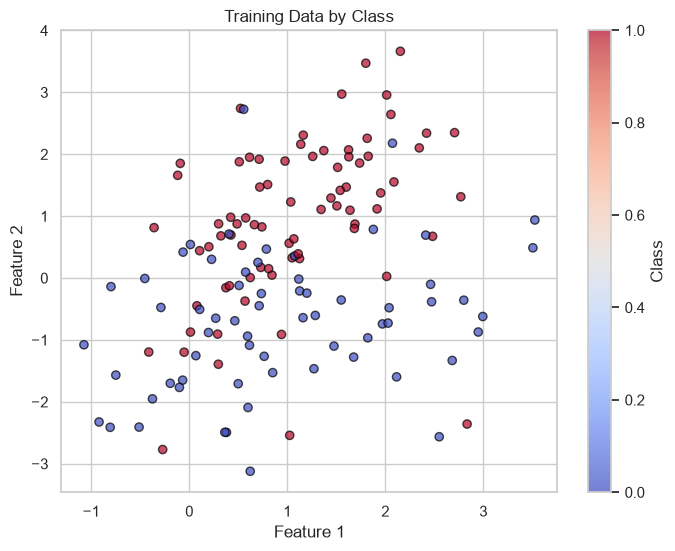

In [9]:
# 1(a)
# Your code here
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train,
    cmap="coolwarm",
    edgecolors="black",
    alpha=0.7
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Training Data by Class")
plt.colorbar(label="Class")
plt.show()

**Your response here:**  
The training data does not appear to be linearly separable. As shown in the scatter plot, the two classes overlap in several regions. Therefore, no single linear decision boundary can perfectly separate all training observations.  

**1(b).** Fit `SVC(kernel='linear', C=1.0, random_state=42)` on the training set. Report training and test accuracy.


In [12]:
# 1(b)
# Your code here
svm_linear = SVC(
    kernel='linear',
    C=1.0,
    random_state=42
)

svm_linear.fit(X_train, y_train)

train_accuracy = accuracy_score(
    y_train, svm_linear.predict(X_train)
)

test_accuracy = accuracy_score(
    y_test, svm_linear.predict(X_test)
)

print("Training Accuracy:", train_accuracy)



Training Accuracy: 0.8


**1(c).** Report the total number of support vectors. Use `n_support_` (which gives one count per class).


In [13]:
# 1(c)
# Your code here
print("Support vectors per class:", svm_linear.n_support_)
print("Total support vectors:", sum(svm_linear.n_support_))

Support vectors per class: [39 38]
Total support vectors: 77


**1(d).** Plot the fitted decision boundary, support vectors, and margin. You may use `plot_decision_boundary` with `support_vectors_` and `plot_margin=True`.


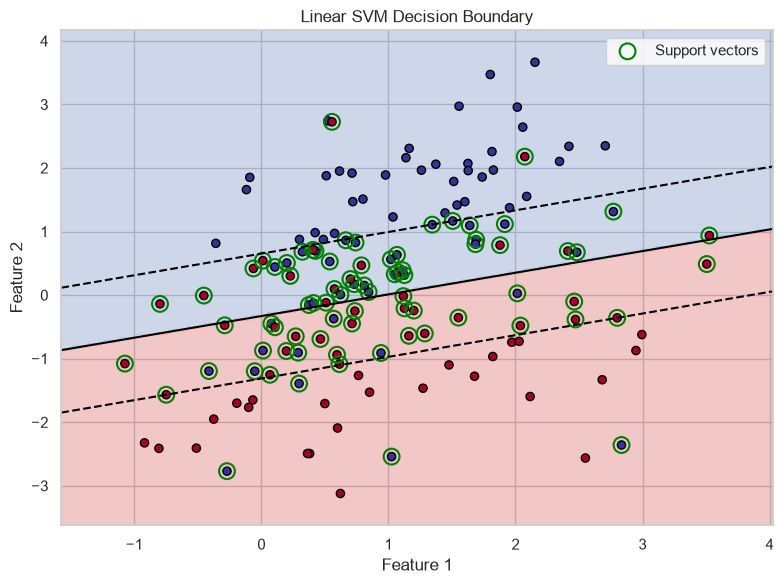

<Axes: title={'center': 'Linear SVM Decision Boundary'}, xlabel='Feature 1', ylabel='Feature 2'>

In [16]:
# 1(d)
# Your code here
plot_decision_boundary(
    X_train,
    y_train,
    svm_linear,
    title="Linear SVM Decision Boundary",
    support_vectors=svm_linear.support_vectors_,
    plot_margin=True
)

### Question 2: Effect of C


**2(a).** Fit three linear SVMs with `C=0.01`, `C=1.0`, and `C=100.0`, using `random_state=42` for each. Keep the fitted models for later steps.


In [15]:
# 2(a)
# Your code here
C_values = [0.01, 1.0, 100.0]

svm_models = {}

for C in C_values:
    model = SVC(
        kernel='linear',
        C=C,
        random_state=42
    )

    model.fit(X_train, y_train)
    svm_models[C] = model

    print(f"C = {C}")
    print("Training Accuracy:", model.score(X_train, y_train))
    print("Test Accuracy:", model.score(X_test, y_test))
    print("Support Vectors:", sum(model.n_support_))
    print()


C = 0.01
Training Accuracy: 0.7857142857142857
Test Accuracy: 0.8
Support Vectors: 114

C = 1.0
Training Accuracy: 0.8
Test Accuracy: 0.8
Support Vectors: 77

C = 100.0
Training Accuracy: 0.8
Test Accuracy: 0.7833333333333333
Support Vectors: 76



**2(b).** For each model, report its total number of support vectors, training accuracy, and test accuracy in a readable table.


In [17]:
# 2(b)
# Your code here
results = []

for C, model in svm_models.items():
    results.append({
        "C": C,
        "Support Vectors": sum(model.n_support_),
        "Training Accuracy": model.score(X_train, y_train),
        "Test Accuracy": model.score(X_test, y_test)
    })

results_df = pd.DataFrame(results)
display(results_df)

,C,Support Vectors,Training Accuracy,Test Accuracy
0,0.01,114,0.785714,0.800000
1,1.00,77,0.800000,0.800000
2,100.00,76,0.800000,0.783333


**2(c).** Show the three decision boundaries in one figure. You may use `compare_svm_parameters`. Describe how the boundaries and margins change as C increases.


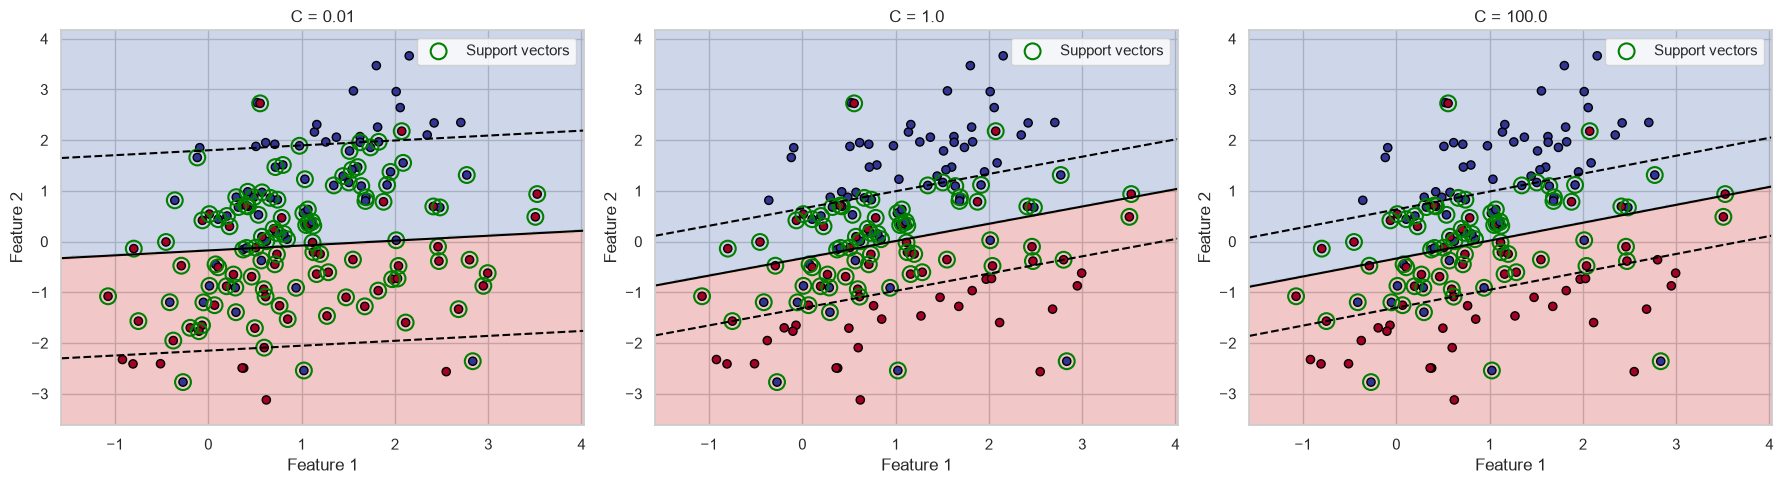

(<Figure size 1800x500 with 3 Axes>,
 array([<Axes: title={'center': 'C = 0.01'}, xlabel='Feature 1', ylabel='Feature 2'>,
        <Axes: title={'center': 'C = 1.0'}, xlabel='Feature 1', ylabel='Feature 2'>,
        <Axes: title={'center': 'C = 100.0'}, xlabel='Feature 1', ylabel='Feature 2'>],
       dtype=object))

In [18]:
# 2(c)
# Your code here
compare_svm_parameters(
    X_train,
    y_train,
    "C",
    [0.01, 1.0, 100.0],
    kernel="linear",
    random_state=42
)

**Your response here:**  
As C increases, the margin generally becomes narrower because the model penalizes margin violations more heavily. The decision boundary also shifts to better accommodate the training observations. The change is more noticeable when C increases from 0.01 to 1.0, while the boundaries for C = 1.0 and C = 100.0 are relatively similar.  


**2(d).** Which C gives the highest observed test accuracy? Which model uses the fewest support vectors? Report both, including ties if present.


**Your response here:**  
The highest observed test accuracy is 80%, achieved by both C = 0.01 and C = 1.0. The model with C = 100.0 uses the fewest support vectors, with 76 support vectors.  

**2(e).** Explain how increasing C can change the bias–variance trade-off. Use your results as evidence without treating a support-vector count alone as a measure of boundary complexity.

**Your response here:**  
Increasing C reduces regularization and penalizes margin violations more heavily. A smaller C generally produces a wider margin, which may result in higher bias and lower variance. A larger C may reduce bias but increase variance and the risk of overfitting.

In our results, increasing C from 0.01 to 1.0 improved training accuracy from 78.57% to 80%, while test accuracy remained at 80%. However, increasing C to 100.0 did not improve training accuracy and reduced test accuracy to 78.33%. This suggests that increasing C beyond 1.0 did not improve generalization in this experiment.

Although the number of support vectors decreased as C increased, this count alone does not measure boundary complexity. All three models use linear decision boundaries.


## Part 2: Nonlinear SVMs and the kernel trick

The RBF kernel can form curved decision boundaries. Its `gamma` parameter controls how locally each training point influences the fitted boundary. Small gamma generally produces smoother boundaries; large gamma can make them more intricate.

### Question 3: Two moons


In [19]:
X_moons, y_moons = make_moons(n_samples=300, noise=0.15, random_state=42)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_moons, y_moons, test_size=0.3, random_state=42,
)


**3(a).** Scatter-plot the moons training data. Could a straight line separate the classes well?


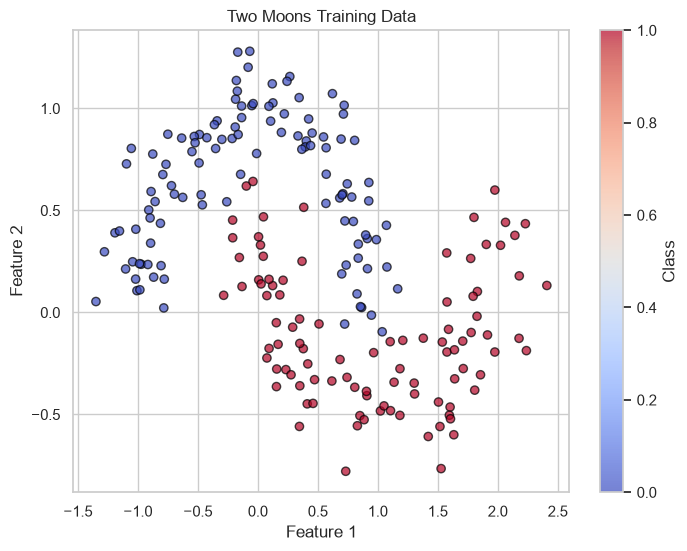

In [20]:
# 3(a)
# Your code here
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_m[:, 0],
    X_train_m[:, 1],
    c=y_train_m,
    cmap="coolwarm",
    edgecolors="black",
    alpha=0.7
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Two Moons Training Data")
plt.colorbar(label="Class")
plt.show()

**Your response here:**
No. The two classes form interleaving crescent-shaped patterns. A straight line cannot effectively separate them because the relationship between the features and class labels is nonlinear.  

**3(b).** Fit a linear SVM (`kernel='linear'`, `C=1.0`, `random_state=42`) and report test accuracy.


In [21]:
# 3(b)
# Your code here
svm_moons_linear = SVC(
    kernel='linear',
    C=1.0,
    random_state=42
)

svm_moons_linear.fit(X_train_m, y_train_m)

linear_test_accuracy = svm_moons_linear.score(
    X_test_m, y_test_m
)

print("Linear SVM Test Accuracy:", linear_test_accuracy)

Linear SVM Test Accuracy: 0.9


**3(c).** Fit an RBF SVM (`kernel='rbf'`, `C=1.0`, `gamma='scale'`, `random_state=42`) and report test accuracy.


In [22]:
# 3(c)
# Your code here
svm_moons_rbf = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    random_state=42
)

svm_moons_rbf.fit(X_train_m, y_train_m)

rbf_test_accuracy = svm_moons_rbf.score(
    X_test_m, y_test_m
)

print("RBF SVM Test Accuracy:", rbf_test_accuracy)

RBF SVM Test Accuracy: 0.9888888888888889


**3(d).** Show the linear and RBF decision boundaries side by side, using the same training data and clearly labeled panels. The plotting helper accepts an `ax` argument.


<Axes: title={'center': 'RBF SVM'}, xlabel='Feature 1', ylabel='Feature 2'>

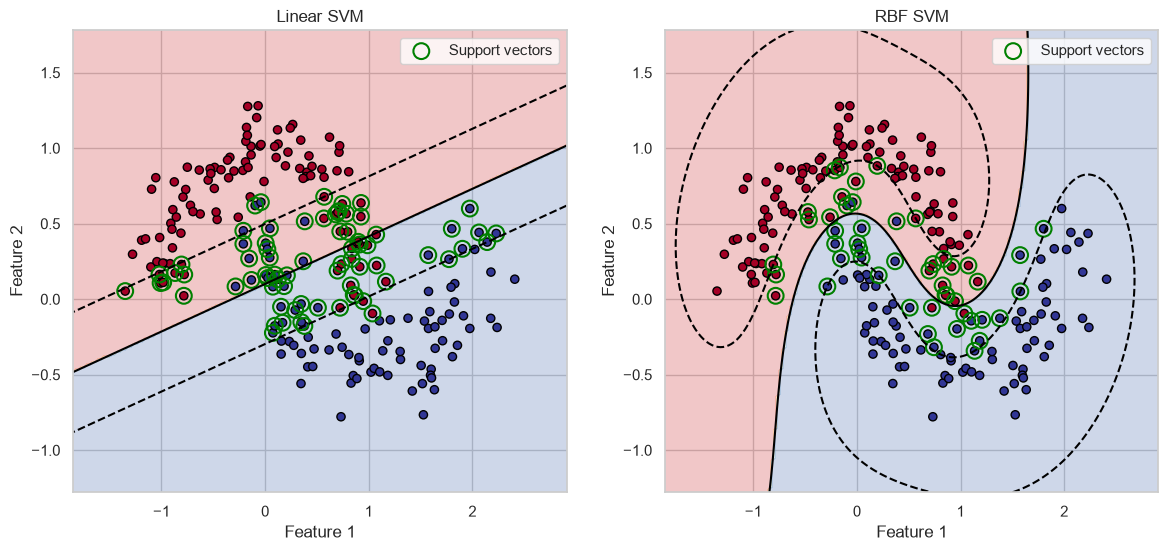

In [24]:
# 3(d)
# Your code here
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

plot_decision_boundary(
    X_train_m,
    y_train_m,
    svm_moons_linear,
    title="Linear SVM",
    ax=axes[0],
    support_vectors=svm_moons_linear.support_vectors_,
    plot_margin=True
)

plot_decision_boundary(
    X_train_m,
    y_train_m,
    svm_moons_rbf,
    title="RBF SVM",
    ax=axes[1],
    support_vectors=svm_moons_rbf.support_vectors_,
    plot_margin=True
)

**3(e).** Explain the difference in observed performance using the shapes of the two boundaries and the moons. If RBF did not score higher, discuss that result rather than assuming it did.


**Your response here:**
The RBF SVM achieved a higher test accuracy (98.89%) than the Linear SVM (90%). The linear decision boundary is a straight line and cannot fully capture the curved structure of the two moons. In contrast, the RBF kernel allows a nonlinear decision boundary that follows the crescent-shaped patterns more closely. This better captures the underlying structure of the data and improves classification performance.  

### Question 4: Tune C and gamma for the RBF model


**4(a).** Use `GridSearchCV` with five folds, training data only, and accuracy scoring to search the C and gamma grid below for an RBF SVM. Keep the fitted search object.


In [25]:
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, 1, 10],
}
# Your code here

grid_search = GridSearchCV(
    estimator=SVC(
        kernel='rbf',
        random_state=42
    ),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy'
)

grid_search.fit(X_train_m, y_train_m)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'C': 10, 'gamma': 10}
Best CV Accuracy: 0.980952380952381


**4(b).** Report the selected C and gamma values from the fitted search.


In [26]:
# 4(b)
# Your code here
print("Best C:", grid_search.best_params_["C"])
print("Best Gamma:", grid_search.best_params_["gamma"])

Best C: 10
Best Gamma: 10


**4(c).** Report the best mean cross-validation accuracy.


In [28]:
# 4(c)
# Your code here
print("Best Mean CV Accuracy:", grid_search.best_score_)

Best Mean CV Accuracy: 0.980952380952381


**4(d).** Use the refitted `best_estimator_` to report test accuracy. `GridSearchCV` refits the best candidate on the full training set by default; do not tune on the test set.


In [29]:
# 4(d)
# Your code here
best_model = grid_search.best_estimator_

best_test_accuracy = best_model.score(
    X_test_m,
    y_test_m
)

print("Best Model Test Accuracy:", best_test_accuracy)


Best Model Test Accuracy: 1.0


**4(e).** Plot a heatmap of mean cross-validation accuracy for every C–gamma combination. Describe the patterns you see.


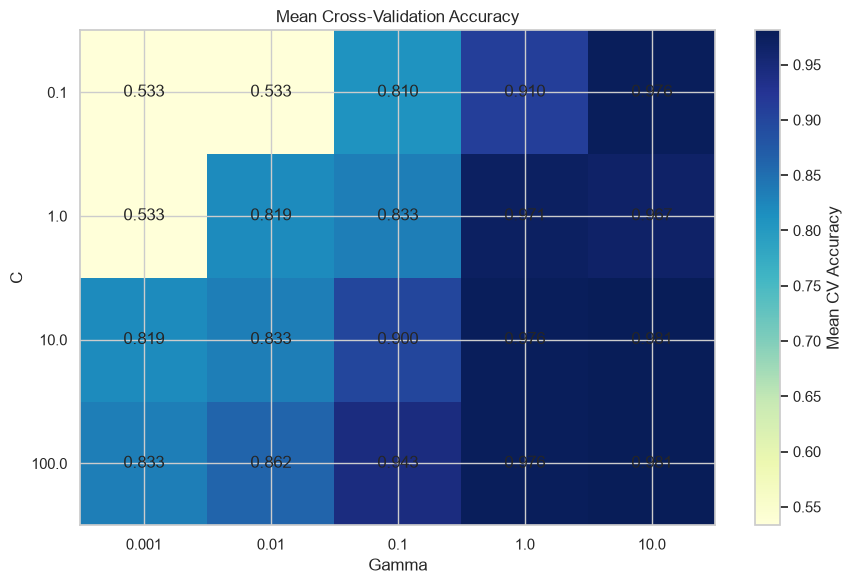

In [30]:
# 4(e)
# Your code here
cv_results = pd.DataFrame(grid_search.cv_results_)

heatmap_data = cv_results.pivot(
    index="param_C",
    columns="param_gamma",
    values="mean_test_score"
)

heatmap_data = heatmap_data.reindex(
    index=param_grid["C"],
    columns=param_grid["gamma"]
)

fig, ax = plt.subplots(figsize=(9, 6))

im = ax.imshow(heatmap_data.values, cmap="YlGnBu", aspect="auto")

ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns)

ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)

ax.set_xlabel("Gamma")
ax.set_ylabel("C")
ax.set_title("Mean Cross-Validation Accuracy")

for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        ax.text(
            j, i,
            f"{heatmap_data.iloc[i, j]:.3f}",
            ha="center",
            va="center"
        )

fig.colorbar(im, ax=ax, label="Mean CV Accuracy")
plt.tight_layout()
plt.show()

**Your response here:**  
The heatmap shows that cross-validation accuracy generally improves as gamma increases. Small gamma values produce relatively poor performance, suggesting that the decision boundary may be too smooth to capture the nonlinear structure of the two moons. Increasing C also improves performance, particularly when gamma is small. For larger gamma values, accuracy becomes consistently high across different C values. The best combination selected by GridSearchCV is C = 10 and gamma = 10, with a mean cross-validation accuracy of approximately 98.10%.  

**4(f).** Fit an RBF SVM with `C=100`, `gamma=10`, and `random_state=42`. Compare its decision boundary and training/test accuracy with the selected model. Does the evidence suggest overfitting?


In [31]:
# 4(f)
# Your code here
extreme_rbf = SVC(
    kernel="rbf",
    C=100,
    gamma=10,
    random_state=42
)

extreme_rbf.fit(X_train_m, y_train_m)

# Compare accuracies
print("Selected Model (C=10, gamma=10)")
print("Training Accuracy:", best_model.score(X_train_m, y_train_m))
print("Test Accuracy:", best_model.score(X_test_m, y_test_m))

print("\nHigh C Model (C=100, gamma=10)")
print("Training Accuracy:", extreme_rbf.score(X_train_m, y_train_m))
print("Test Accuracy:", extreme_rbf.score(X_test_m, y_test_m))

Selected Model (C=10, gamma=10)
Training Accuracy: 1.0
Test Accuracy: 1.0

High C Model (C=100, gamma=10)
Training Accuracy: 1.0
Test Accuracy: 1.0


**Your response here:**  
The selected model (C = 10, gamma = 10) and the high C model (C = 100, gamma = 10) both achieved 100% training accuracy and 100% test accuracy. Increasing C did not improve training accuracy or reduce test accuracy. Therefore, the observed results do not provide evidence of overfitting. Although a larger C may produce a more tightly fitted decision boundary, both models generalize equally well on this test set.

## Part 3: Wine recognition with SVMs

The built-in `load_wine` data contains 178 samples, 13 chemical measurements, and three cultivar classes. For this lab, convert it to a binary target: original class 0 versus original classes 1 and 2. Scale features within a fitted pipeline so training statistics are never learned from the held-out test set.

### Question 5: Inspect and prepare the wine data


In [27]:
wine = load_wine()
X_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
y_wine_binary = pd.Series((wine.target > 0).astype(int), name="other_cultivar")


**5(a).** Report the number of samples and features.


In [32]:
# 5(a)
# Your code here
print("Number of samples:", X_wine.shape[0])
print("Number of features:", X_wine.shape[1])

Number of samples: 178
Number of features: 13


**5(b).** Report each binary class's count and percentage. Is the dataset approximately balanced? Explain your judgment.


In [33]:
# 5(b)
# Your code here
class_counts = y_wine_binary.value_counts().sort_index()
class_percentages = y_wine_binary.value_counts(normalize=True).sort_index() * 100

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_percentages
})

display(class_summary)

,Count,Percentage (%)
other_cultivar,,
0,59,33.146067
1,119,66.853933


**Your response here:**  
The dataset is not approximately balanced. Class 0 contains 59 samples (33.15%), while Class 1 contains 119 samples (66.85%). Class 1 has approximately twice as many observations as Class 0, indicating a moderate class imbalance.


**5(c).** Split the binary wine data into 70% training and 30% test using `random_state=42`. Keep the test set for final evaluation.


In [34]:
# 5(c)
# Your code here
X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_wine,
    y_wine_binary,
    test_size=0.3,
    random_state=42
)

print("Training samples:", X_train_w.shape[0])
print("Test samples:", X_test_w.shape[0])

Training samples: 124
Test samples: 54


**5(d).** Define a scikit-learn `Pipeline` with `StandardScaler` followed by a linear `SVC(C=1.0, random_state=42)`. Use this pipeline pattern for the kernel comparison so scaling is fit on training data only.


In [35]:
# 5(d)
# Your code here
wine_linear_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(
        kernel="linear",
        C=1.0,
        random_state=42
    ))
])

wine_linear_pipeline.fit(X_train_w, y_train_w)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['alcohol','malic_acid','ash',...,'hue','od280/od315_of_diluted_wines', 'proline']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


# Lab 06: Support Vector Machines

Complete all nine questions in order. Put code in the code response cells and explanations in the Markdown response cells beside each prompt. Restart the kernel and run the whole notebook before submitting. Label plots with titles, axes, and legends where relevant.

This lab uses three datasets: a synthetic two-feature classification problem, two interlocking moons, and the built-in wine recognition dataset. The last part uses a synthetic imbalanced dataset. No download is required.


### Question 6: Compare SVM kernels


**6(a).** Fit three scaling pipelines on the wine training data: linear (`C=1.0`), polynomial (`degree=3`, `C=1.0`), and RBF (`C=1.0`, `gamma='scale'`). Set `random_state=42` on each SVC. Save each fitted pipeline.


In [36]:
# 6(a)
# Your code here
wine_pipelines = {
    "Linear": Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(
            kernel="linear",
            C=1.0,
            random_state=42
        ))
    ]),

    "Polynomial": Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(
            kernel="poly",
            degree=3,
            C=1.0,
            random_state=42
        ))
    ]),

    "RBF": Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            random_state=42
        ))
    ])
}

for name, pipeline in wine_pipelines.items():
    pipeline.fit(X_train_w, y_train_w)
    print(f"{name} pipeline fitted.")

Linear pipeline fitted.
Polynomial pipeline fitted.
RBF pipeline fitted.


**6(b).** For each kernel, report training accuracy, test accuracy, total support vectors, and training time in seconds. Measure training time with `time.perf_counter()`. The fitted SVC is available through its pipeline's `named_steps`.


In [37]:
# 6(b)
# Your code here
results = []

for name, pipeline in wine_pipelines.items():

    start_time = time.perf_counter()

    pipeline.fit(X_train_w, y_train_w)

    training_time = time.perf_counter() - start_time

    train_accuracy = pipeline.score(
        X_train_w, y_train_w
    )

    test_accuracy = pipeline.score(
        X_test_w, y_test_w
    )

    svc = pipeline.named_steps["svc"]

    total_support_vectors = svc.n_support_.sum()

    results.append({
        "Kernel": name,
        "Training Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Support Vectors": total_support_vectors,
        "Training Time (seconds)": training_time
    })

results_df = pd.DataFrame(results)

display(results_df)

,Kernel,Training Accuracy,Test Accuracy,Support Vectors,Training Time (seconds)
0,Linear,1.000000,0.981481,12,0.025427
1,Polynomial,0.967742,0.962963,56,0.001642
2,RBF,1.000000,1.000000,37,0.001352


**6(c).** Which kernel has the highest observed test accuracy? State any ties.


**Your response here:**  
The RBF kernel achieved the highest observed test accuracy of 100%. It performed better than both the linear kernel (98.15%) and the polynomial kernel (96.30%).


**6(d).** Plot a confusion matrix for a model with the highest observed test accuracy. Label the binary classes.


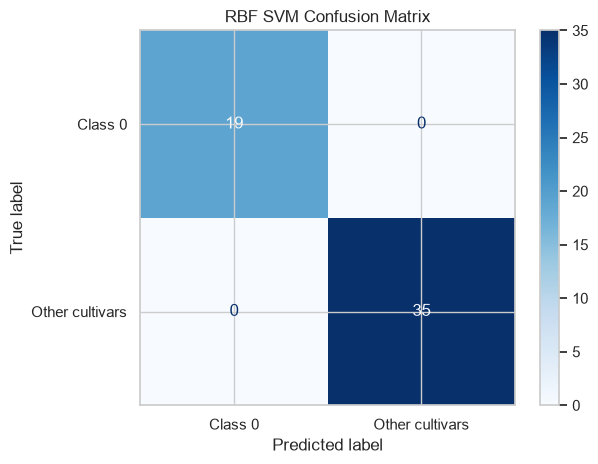

In [38]:
# 6(d)
# Your code here
best_wine_model = wine_pipelines["RBF"]

ConfusionMatrixDisplay.from_estimator(
    best_wine_model,
    X_test_w,
    y_test_w,
    display_labels=["Class 0", "Other cultivars"],
    cmap="Blues"
)

plt.title("RBF SVM Confusion Matrix")
plt.tight_layout()
plt.show()


**6(e).** Would you recommend an SVM for this task? Use the observed scores, confusion matrix, training time, and interpretability in your explanation.


**Your response here:**
Yes, I would recommend an SVM for this classification task. The RBF kernel achieved the highest test accuracy of 100%, correctly classifying all 54 test observations. Its confusion matrix shows 19 true negatives and 35 true positives, with no false positives or false negatives.

All three models also had very short training times. The RBF model took approximately 0.001352 seconds to train, making it computationally efficient for this dataset.

However, interpretability is an important consideration. A linear SVM is easier to interpret through its feature coefficients, while an RBF SVM produces a nonlinear decision boundary that is more difficult to explain.

Overall, I would recommend the RBF SVM when predictive performance is the primary objective. However, the perfect test accuracy should be interpreted cautiously because it was evaluated on only 54 observations from a single train-test split.


### Question 7: Coefficients of a linear SVM


**7(a).** Fit a linear SVM in a scaling pipeline on the wine training set (or reuse the fitted linear pipeline from Question 6).


In [39]:
# 7(a)
# Your code here
linear_wine_model = wine_pipelines["Linear"]

linear_wine_model.fit(X_train_w, y_train_w)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['alcohol','malic_acid','ash',...,'hue','od280/od315_of_diluted_wines', 'proline']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


**7(b).** Extract its `coef_` vector and associate each coefficient with the corresponding feature name. The coefficients are for standardized features.


In [40]:
# 7(b)
# Your code here
svc = linear_wine_model.named_steps["svc"]

coefficients = svc.coef_.ravel()

coef_df = pd.DataFrame({
    "Feature": X_wine.columns,
    "Coefficient": coefficients
})

display(coef_df)

,Feature,Coefficient
0,alcohol,-0.821343
1,malic_acid,-0.223593
2,ash,-0.637935
3,alcalinity_of_ash,1.016674
4,magnesium,-0.095908
5,total_phenols,-0.396527
6,flavanoids,-0.339151
7,nonflavanoid_phenols,-0.073646
8,proanthocyanins,0.201124
9,color_intensity,0.286082


**7(c).** Draw a horizontal bar chart of absolute coefficient values for all features, sorted from largest to smallest.


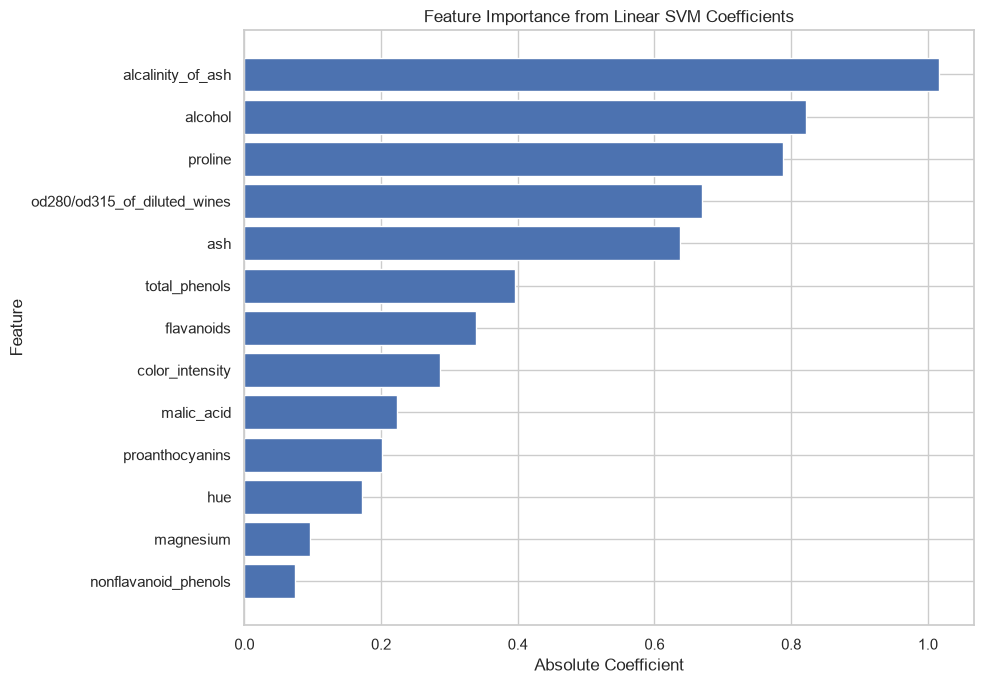

In [41]:
# 7(c)
# Your code here
coef_df["Absolute Coefficient"] = (
    coef_df["Coefficient"].abs()
)

coef_sorted = coef_df.sort_values(
    "Absolute Coefficient",
    ascending=False
)

plt.figure(figsize=(10, 7))

plt.barh(
    coef_sorted["Feature"],
    coef_sorted["Absolute Coefficient"]
)

plt.gca().invert_yaxis()

plt.xlabel("Absolute Coefficient")
plt.ylabel("Feature")
plt.title("Feature Importance from Linear SVM Coefficients")

plt.tight_layout()
plt.show()

**7(d).** Which three features have the largest absolute coefficients?


**Your response here:**
The three features with the largest absolute coefficients are alcalinity_of_ash, alcohol, and proline.

**7(e).** Explain why the linear SVM has one coefficient per feature and why the RBF SVM does not have the same directly interpretable `coef_` vector. Interpret magnitudes with the standardization in mind.


**Your response here:**  
A linear SVM has one coefficient for each feature because its decision function is a weighted sum of the input features. Each coefficient represents the contribution of one feature to the decision score.

An RBF SVM does not have the same directly interpretable coefficient vector because its decision function is based on kernel similarities between observations and support vectors rather than a single linear combination of the original features.

Since the features were standardized using StandardScaler, the linear coefficients represent the effect of a one-standard-deviation increase in each feature, holding the other features constant. Larger absolute coefficients indicate a stronger contribution to the decision score, while the sign indicates the direction of that contribution.

## Part 4: Imbalanced classification

Accuracy can hide weak minority-class performance. Compare precision, recall, F1, and confusion matrices for a standard and a class-weighted SVM. Treat class 1 as the minority class.

### Question 8: Baseline on imbalanced data


In [42]:
X_imb, y_imb = make_classification(
    n_samples=1000, n_features=20, n_informative=15, n_redundant=5,
    n_classes=2, weights=[0.95, 0.05], flip_y=0.01, random_state=42,
)
X_train_imb, X_test_imb, y_train_imb, y_test_imb = train_test_split(
    X_imb, y_imb, test_size=0.3, random_state=42, stratify=y_imb,
)


**8(a).** Report both training-set class counts and the majority-to-minority count ratio.


In [43]:
# 8(a)
# Your code here
class_counts = pd.Series(y_train_imb).value_counts().sort_index()

majority_count = class_counts.max()
minority_count = class_counts.min()

count_ratio = majority_count / minority_count

print("Class Counts:")
print(class_counts)

print("Majority-to-Minority Ratio:", count_ratio)

Class Counts:
0    663
1     37
Name: count, dtype: int64
Majority-to-Minority Ratio: 17.91891891891892


**8(b).** Fit a standard RBF SVM (`C=1.0`, `gamma='scale'`, `random_state=42`) in a `StandardScaler` pipeline, with no class weighting. Report test accuracy and precision, recall, and F1 for both classes using `classification_report`.


In [44]:
# 8(b)
# Your code here
imb_rbf = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    ))
])

imb_rbf.fit(X_train_imb, y_train_imb)

y_pred_imb = imb_rbf.predict(X_test_imb)

print(classification_report(
    y_test_imb,
    y_pred_imb,
    target_names=["Majority (Class 0)", "Minority (Class 1)"],
    zero_division=0
))


                    precision    recall  f1-score   support

Majority (Class 0)       0.96      1.00      0.98       284
Minority (Class 1)       1.00      0.19      0.32        16

          accuracy                           0.96       300
         macro avg       0.98      0.59      0.65       300
      weighted avg       0.96      0.96      0.94       300



**8(c).** Assess minority-class performance. Explain why overall accuracy alone may be misleading here.


**Your response here:**  
Overall accuracy can be misleading because the dataset is highly imbalanced. A model could achieve high accuracy by predicting mostly the majority class while failing to identify minority-class observations. Therefore, minority-class recall, precision, and F1-score are important for evaluating how well the model identifies the less frequent class.


### Question 9: Class weights


**9(a).** Fit the same scaling and RBF SVM pipeline with `class_weight='balanced'`.


In [45]:
# 9(a)
# Your code here
imb_rbf_balanced = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        random_state=42
    ))
])

imb_rbf_balanced.fit(X_train_imb, y_train_imb)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


**9(b).** Report the same test metrics as in 8(b), and describe how minority-class performance changed.


In [46]:
# 9(b)
# Your code here
y_pred_balanced = imb_rbf_balanced.predict(X_test_imb)

print(classification_report(
    y_test_imb,
    y_pred_balanced,
    target_names=["Majority (Class 0)", "Minority (Class 1)"],
    zero_division=0
))

                    precision    recall  f1-score   support

Majority (Class 0)       0.99      0.98      0.98       284
Minority (Class 1)       0.65      0.81      0.72        16

          accuracy                           0.97       300
         macro avg       0.82      0.89      0.85       300
      weighted avg       0.97      0.97      0.97       300



**Your response here:**  
The balanced RBF SVM achieved an overall accuracy of 96.67%. For Class 1 (the minority class), precision was 0.65, recall was 0.81, and the F1-score was 0.72. Compared with the standard model, minority-class recall increased substantially from 18.75% to 81.25%. However, precision decreased because the balanced model classified more majority-class observations as minority-class observations. Overall, class weighting significantly improved the model's ability to identify minority-class observations.

**9(c).** Show confusion matrices for the standard and balanced models. What trade-off do you observe between missed minority cases and false alarms?


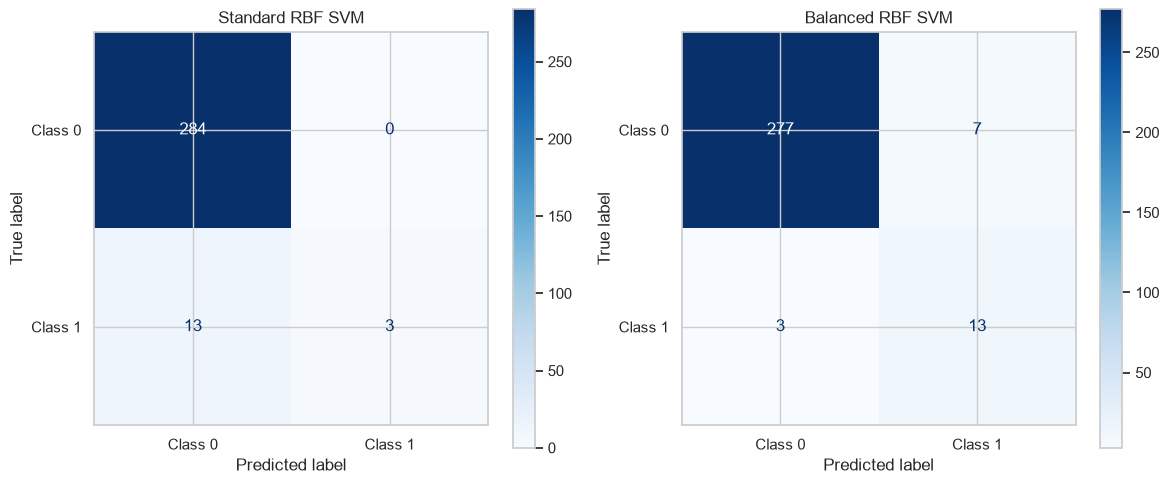

In [47]:
# 9(c)
# Your code here
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(
    imb_rbf,
    X_test_imb,
    y_test_imb,
    display_labels=["Class 0", "Class 1"],
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Standard RBF SVM")

ConfusionMatrixDisplay.from_estimator(
    imb_rbf_balanced,
    X_test_imb,
    y_test_imb,
    display_labels=["Class 0", "Class 1"],
    cmap="Blues",
    ax=axes[1]
)

axes[1].set_title("Balanced RBF SVM")

plt.tight_layout()
plt.show()

**Your response here:**
The standard model produced 13 false negatives and 0 false positives, while the balanced model produced 3 false negatives and 7 false positives. By using class weighting, the model reduced missed minority-class cases by 10, improving minority-class recall from 18.75% to 81.25%. However, this came at the cost of 7 false alarms. This demonstrates a trade-off between identifying more minority-class observations and incorrectly classifying majority-class observations as minority cases.


**9(d).** Use five-fold `GridSearchCV` on the training set to tune C and class weight simultaneously, using `scoring='f1'`. Keep scaling inside the pipeline, and use pipeline parameter names such as `svc__C`. Search the grid below.


In [52]:
param_grid_imb = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__class_weight": [None, "balanced", {0: 1, 1: 10}, {0: 1, 1: 20}],
}
# Your code here
imb_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(
        kernel="rbf",
        gamma="scale",
        random_state=42
    ))
])

grid_search_imb = GridSearchCV(
    estimator=imb_pipeline,
    param_grid=param_grid_imb,
    cv=5,
    scoring="f1"
)

grid_search_imb.fit(X_train_imb, y_train_imb)

print("Grid Search completed.")

Grid Search completed.


**9(e).** Report the selected C and class weight, and the corresponding mean cross-validation F1.


In [53]:
# 9(e)
# Your code here
print("Best C:", grid_search_imb.best_params_["svc__C"])

print(
    "Best Class Weight:",
    grid_search_imb.best_params_["svc__class_weight"]
)

print(
    "Best Mean CV F1:",
    grid_search_imb.best_score_
)

Best C: 1
Best Class Weight: {0: 1, 1: 10}
Best Mean CV F1: 0.6902747252747252


**9(f).** For the refitted best model, report test-set class-1 F1, precision, and recall. Compare them with the standard and balanced models without changing the selected model based on test results.


In [56]:
# 9(f)
# Your code here
best_imb_model = grid_search_imb.best_estimator_

models_to_compare = {
    "Standard": imb_rbf,
    "Balanced": imb_rbf_balanced,
    "Tuned": best_imb_model
}

comparison = []

for name, model in models_to_compare.items():
    predictions = model.predict(X_test_imb)

    comparison.append({
        "Model": name,
        "Class 1 Precision": precision_score(
            y_test_imb, predictions, pos_label=1, zero_division=0
        ),
        "Class 1 Recall": recall_score(
            y_test_imb, predictions, pos_label=1, zero_division=0
        ),
        "Class 1 F1": f1_score(
            y_test_imb, predictions, pos_label=1, zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df)

,Model,Class 1 Precision,Class 1 Recall,Class 1 F1
0,Standard,1.000000,0.1875,0.315789
1,Balanced,0.650000,0.8125,0.722222
2,Tuned,0.733333,0.6875,0.709677


**Your response here:**
The grid search selected C = 1 and class_weight = {0: 1, 1: 10}, with a mean 5-fold CV F1 of 0.690. On the test set, the tuned model achieved class-1 precision of 0.733, recall of 0.688, and F1 of 0.710.
The standard model (no class weighting) has perfect precision (1.000) but very low recall (0.188), giving an F1 of only 0.316. It rarely predicts the minority class, so the few positives it flags are correct, but it misses most of them. The balanced model pushes recall up to 0.813 at the cost of lower precision (0.650), reaching an F1 of 0.722. The tuned model falls between the two, trading some recall for higher precision, with an F1 of 0.710.
The balanced model has a slightly higher test F1 than the tuned model (0.722 vs. 0.710). We still keep the tuned model, because it was selected by cross-validation on the training set only. Switching models based on test results would use the test set for model selection and bias our estimate of generalization performance. With only about 16 positive cases in the test set, a difference of 0.012 in F1 is also within the noise from one or two predictions.


## Submission check

- Every code and written-response cell is complete.
- Figures have readable titles, axis labels, and legends where needed.
- The notebook runs in order after a kernel restart.
- `lab-06.ipynb` and your generated `uv.lock` are committed and pushed to your private submission repository.
